# Project 1

Welcome to the first NLP1 project. The goal of the first tutorial was to get you familiar with text segmentation and simple text classification for topic detection.
Given the skills you have developed in the first week, you will now be applying them within a different dataset and task.

We are recommending a set of tasks and associated datasets; using those, you will be experimenting on problems introduced during the tutorials. You will be applying hands-on the experiments you have already explored in the last tutorial, and taking a deeper dive: extending your experiments, trying different set ups, possibly considering different evaluation techniques and analysing errors. 

The week after the deadline, your TA will perform a short oral assessment of the skills and knowledge you acquired (make sure to check the official schedule for this), probing you to answer questions about what you learnt, about what you did and about why you did the things you did (as opposed to some reasonable alternatives) as well as pros and cons of your method, and so on. 

As the tutorials will be building upon your knowledge throughout the weeks, the task and dataset you choose now will be the ones you use in projects 2 and 3; and the ones you will be finally writing about in your final blog post.  

## Get to work!

The next section has a checklist to help you not lose track of what needs to be done. Here we have a more informal guide, with prompts and questions for you. 


1. [Choose a dataset](http://nlp-illc.github.io/nlp1/). Spend some time understanding how the dataset looks and some statistics of it (e.g. how many instances of each classification label we have?)
2. Remember what we learnt during the tutorial: to develop any classifier of the kind we saw, we needed a way to segment text. Do you want to use the tokeniser we have developed? Do you need to train a new one? If you do, what hyperparameters shall you use? What data shall you use to train it? Consider that your dataset may be too small to train a tokeniser! Think whether you will need a larger resource of similar nature to train a tokeniser.
3. Start thinking how to represent your documents into features. We have experimented with token occurences and frequencies. Can you think of any other ways, possibly? 
4. We had experimented with Logistic Regression and a shallow neural network. You can experiment with and assess different architectures now and their hyper parameters (e.g. add layers, possibly change the activation functions, drop out rates).
5. Evaluate your models! Was the evaluation method adequate for your new experimental setup? Do you want to assess other aspects of performance?
6. Analyse the various models you assessed and try to decide on which is the best.

Be mindful that you will be using your experiments to write up your final blog, so make sure they are clean and neat!

You can write your own code and you can reuse code from the tutorial and its packages or from other sources. You may use coding assistants if you like, but use it mindfully as you take full responsibility for this kind of (semi-)automated coding. Also, keep a record of the kinds of things you delegate to any form of assistant, as you will be asked to disclose this in your blog post (not because we will pass a value judgement on it, but because it is a widespread and good practice to document such things).

You may use jupyter notebooks or python files, it's up to you as we will not directly assess your code. But, once again, be organised, as we will ask you to share a reproducible version of your experiments along with your blog post (again, because this is how real research is publicised). 

If you are unsure about anything, ask your TA! They are always happy to help you! Happy coding! :)

## Checklist

What **we expect you to do**:

- [ ] Compare different systems of text classification for your choice of data/task.
- Your comparisons should cover:
    - [ ] the two representation spaces in the tutorial (token indicators and bag-of-words) and an additional one of your choice.
    - [ ] the two kinds of architectures in the tutorial (log-linear and single-hidden-layer MLP) and an additional one of your choice (such as a modification of the MLP).
- [ ] Your comparisons must be based on cross-validation and a relevant metric (accuracy or else).
- [ ] You should make use of Bayesian estimation to help you analyse results in relation to a region of practical equivalence (ROPE), and you can motivate the ROPE size yourself.

What you need to **bring to the oral assessment**:
* You will be asked questions about the points above, you can bring a slide deck with up to five slides (one for each of the following topics _data and metrics_, _features_, _architectures_, _results_, _extra_); you _will not_ give a presentation, rather, these slides are to be thought of as "backup slides" that you can use to guide your answers to the questions the TA will ask you.
* You may also be asked questions about the tutorial, for those, you don't need to prepare any deliverable (a good way to prepare is to work through the tutorial and reflect on the questions there).

What you should **keep in mind** given that you will eventually write a blog post about your work throughout the course:
* Organise your code;
* Summarise your motivations and findings;
* Document your sources and any form of AI-assistance you use.

# Baselines on PAWS

In this notebook we run the baselines of the tutorial on PAWS (paraphrase identification): BPE tokenizers (with and without cleanup), token indicator and bag-of-words encoders, and log-linear softmax regression and a one-hidden-layer MLP. Every system is evaluated with 5-fold cross validation repeated for several seeds, compared with Bayesian estimation in relation to a ROPE, and finally ensembled and evaluated once on the test set.

All settings live in `config.py`; the code lives in the `.py` files in this folder. Methodology choices are documented in `choices.md`.

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning) 

In [3]:
# helper modules for this notebook (see the .py files in this folder)
import sys
from pathlib import Path

# Assuming the working directory is root/part1/baseline
root = Path.cwd().parents[1]
sys.path.insert(0, str(root))

from part1 import baseline
from part1.baseline import config

In [4]:
import itertools
import pandas as pd
from collections import OrderedDict
from sklearn.metrics import accuracy_score, classification_report

print(f"Device: {config.DEVICE}")

# save models and outputs there to keep the directory tree organised
results_folder = Path(config.RESULTS_FOLDER)
results_folder.mkdir(parents=True, exist_ok=True) 
results_folder

Device: cpu


WindowsPath('results')

# Data

We use PAWS-Wiki (Paraphrase Adversaries from Word Scrambling), a collection of sentence pairs from Wikipedia labelled as paraphrase or not paraphrase. The pairs were generated by word swapping and back translation, so both sentences of a pair share most of their words, whether they are paraphrases or not.

> Yuan Zhang, Jason Baldridge, Luheng He. [PAWS: Paraphrase Adversaries from Word Scrambling.](https://arxiv.org/abs/1904.01130) NAACL 2019.

* `labeled_final`: human-labelled pairs (train, validation and test splits).
* `unlabeled_final`: a much larger collection of automatically generated pairs; we only use its sentences (not its labels) to train tokenizers.

In [5]:
paws_outcome_space = baseline.data.paws_outcome_space
print(paws_outcome_space)

0: not paraphrase, 1: paraphrase


In [6]:
labeled, unlabeled = baseline.data.download_paws()
print(labeled)
print(unlabeled)

DatasetDict({
    train: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 49401
    })
    test: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 8000
    })
    validation: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 8000
    })
})
DatasetDict({
    train: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 645652
    })
    validation: Dataset({
        features: ['id', 'sentence1', 'sentence2', 'label'],
        num_rows: 10000
    })
})


## Dataset size and labels

In [7]:
baseline.dataset_analysis.split_sizes({'labeled_final': labeled, 'unlabeled_final': unlabeled})

,dataset,split,pairs
0,labeled_final,train,49401
1,labeled_final,test,8000
2,labeled_final,validation,8000
3,unlabeled_final,train,645652
4,unlabeled_final,validation,10000


In [8]:
baseline.dataset_analysis.label_counts(labeled, paws_outcome_space)

,split,label,count,fraction
0,train,not paraphrase,27572,0.558126
1,train,paraphrase,21829,0.441874
2,test,not paraphrase,4464,0.558000
3,test,paraphrase,3536,0.442000
4,validation,not paraphrase,4461,0.557625
5,validation,paraphrase,3539,0.442375


We merge the labelled train and validation splits for cross validation, and keep the test split completely unseen until the very end.

In [9]:
cv_pairs = baseline.data.to_pairs(labeled["train"]) + baseline.data.to_pairs(labeled["validation"])
test_pairs = baseline.data.to_pairs(labeled["test"])
cv_sentences = baseline.data.sentences_of(cv_pairs)
print(f"Cross-validation pairs: {len(cv_pairs)}, test pairs: {len(test_pairs)}, cross-validation sentences: {len(cv_sentences)}")

Cross-validation pairs: 57401, test pairs: 8000, cross-validation sentences: 114802


Have a look at some pairs:

In [10]:
print(baseline.dataset_analysis.example_pairs(cv_pairs, paws_outcome_space, num_examples=3))

Label: not paraphrase
s1  The Puerto Inca Province is the largest of eleven provinces of the Huánuco Region in Peru .
s2  The region of Huánuco is the largest of the eleven provinces of the Province of Puerto Inca in Peru .

s1  Babbar Khalsa is listed as a terrorist organisation by the United States , the EU , Canada , India , and the United Kingdom .
s2  Babbar Khalsa is performed by the United States , the EU , Canada , India and the United Kingdom as a terrorist organisation .

s1  He mainly produced portraits , and was repeatedly used by the Spanish , and also the Austrian , Habsburgs .
s2  He repeatedly produced portraits and was mainly used by the Spanish and also Austrian Habsburgs .


Label: paraphrase
s1  Vonberg studied at Imperial College then joined the Cavendish Laboratory in 1945 where he worked with Martin Ryle .
s2  Vonberg studied at Imperial College and joined the Cavendish Laboratory where he worked with Martin Ryle in 1945 .

s1  In March 2008 , Sophina participate

# Dataset Analysis

## Sentence lengths

Length in `wordpunct_tokenize` tokens of every sentence in the cross-validation data.

Lengths:   0%|          | 0/57401 [00:00<?, ?it/s]

                            count       mean       std  min   25%   50%   75%  \
label          sentence                                                         
not paraphrase sentence1  32033.0  21.693972  5.640376  5.0  17.0  22.0  26.0   
               sentence2  32033.0  21.694565  5.625775  2.0  17.0  22.0  26.0   
paraphrase     sentence1  25368.0  21.679518  5.618348  5.0  17.0  22.0  26.0   
               sentence2  25368.0  21.658586  5.605231  5.0  17.0  22.0  26.0   

                           max  
label          sentence         
not paraphrase sentence1  58.0  
               sentence2  58.0  
paraphrase     sentence1  58.0  
               sentence2  58.0  


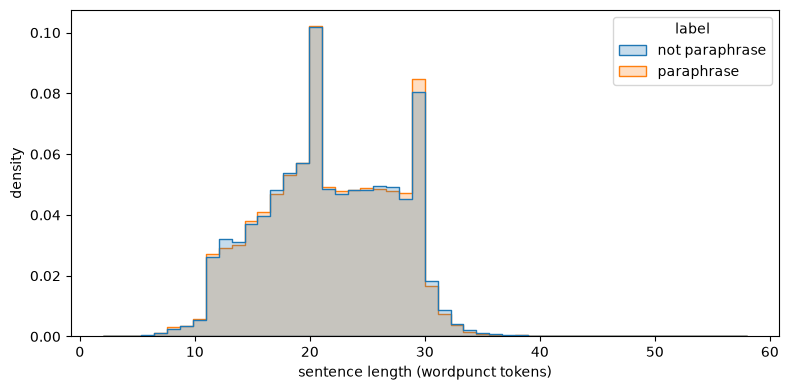

In [11]:
lengths = baseline.dataset_analysis.sentence_lengths(cv_pairs, paws_outcome_space)
print(lengths.groupby(['label', 'sentence'])['length'].describe())
baseline.dataset_analysis.plot_histogram_per_label(lengths, 'length', 'sentence length (wordpunct tokens)')

## Word overlap

Jaccard index of the sets of (lowercased) words of sentence1 and sentence2. If both labels have similar (high) overlap, models that only see _which_ words occur will struggle.

Overlap:   0%|          | 0/57401 [00:00<?, ?it/s]

                  count      mean       std       min       25%       50%  \
label                                                                       
not paraphrase  32033.0  0.886725  0.072760  0.047619  0.840000  0.882353   
paraphrase      25368.0  0.887327  0.063078  0.384615  0.846154  0.882353   

                     75%  max  
label                          
not paraphrase  0.937500  1.0  
paraphrase      0.928571  1.0  


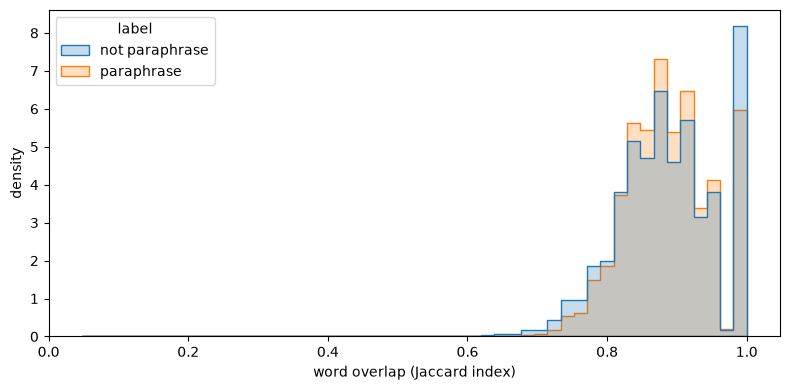

In [12]:
overlap = baseline.dataset_analysis.word_overlap(cv_pairs, paws_outcome_space)
print(overlap.groupby('label')['overlap'].describe())
baseline.dataset_analysis.plot_histogram_per_label(overlap, 'overlap', 'word overlap (Jaccard index)')

## Heaps' Law

Vocabulary growth $V(n) = Kn^\beta$ for the NLTK tokenizers from the tutorial, on the sentences of the cross-validation data.

In [13]:
import nltk
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\joeyl\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [14]:
%%time
heaps_tokens = baseline.dataset_analysis.heaps_tokens(cv_sentences)
heaps_curves = baseline.dataset_analysis.heaps_curves(heaps_tokens)
heaps_fits = baseline.dataset_analysis.heaps_fits(heaps_curves)

Tokenizing:   0%|          | 0/114802 [00:00<?, ?it/s]

NLTK Word: 2450652 tokens
WordPunct: 2489266 tokens
Treebank: 2450372 tokens
Tweet: 2499288 tokens
Whitespace: 2450372 tokens


Counting:   0%|          | 0/5 [00:00<?, ?it/s]

NLTK Word   : K=192.017, beta=0.3649, R²=0.9373
WordPunct   : K=205.077, beta=0.3575, R²=0.9345
Treebank    : K=190.995, beta=0.3654, R²=0.9376
Tweet       : K=191.459, beta=0.3645, R²=0.9374
Whitespace  : K=191.054, beta=0.3654, R²=0.9376
CPU times: total: 55.4 s
Wall time: 57.7 s


c:\Users\joeyl\Documents\GitHub\nlp1-student\part1\baseline\dataset_analysis.py:222: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
c:\Users\joeyl\Documents\GitHub\nlp1-student\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


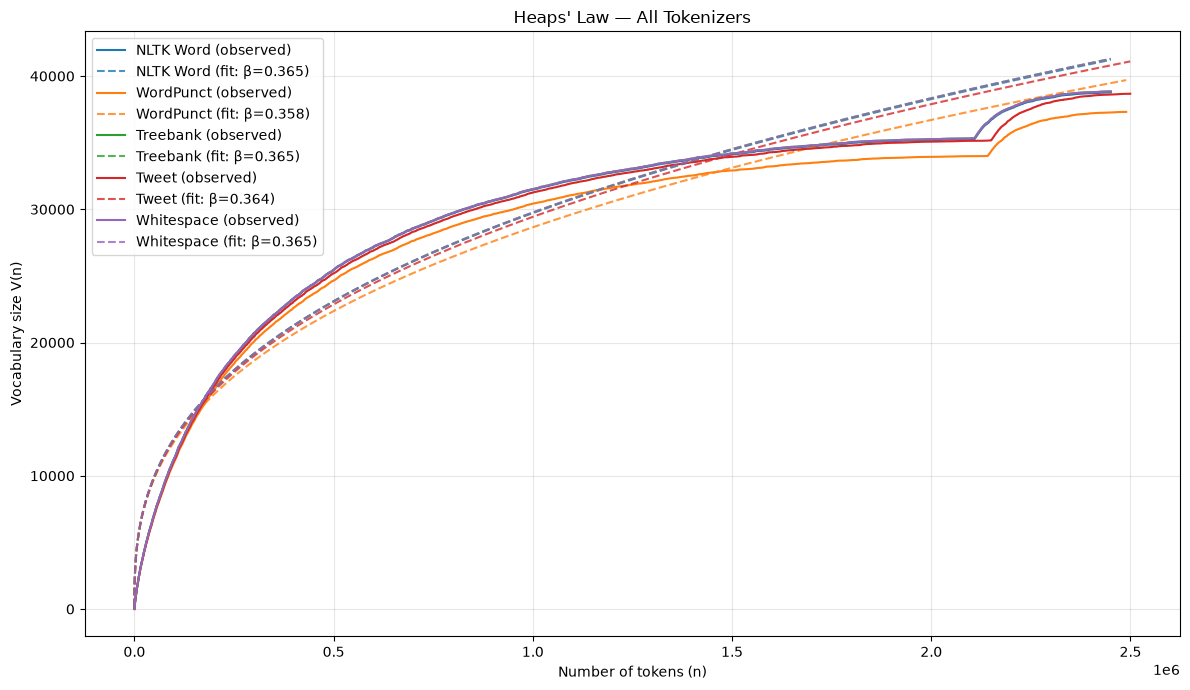

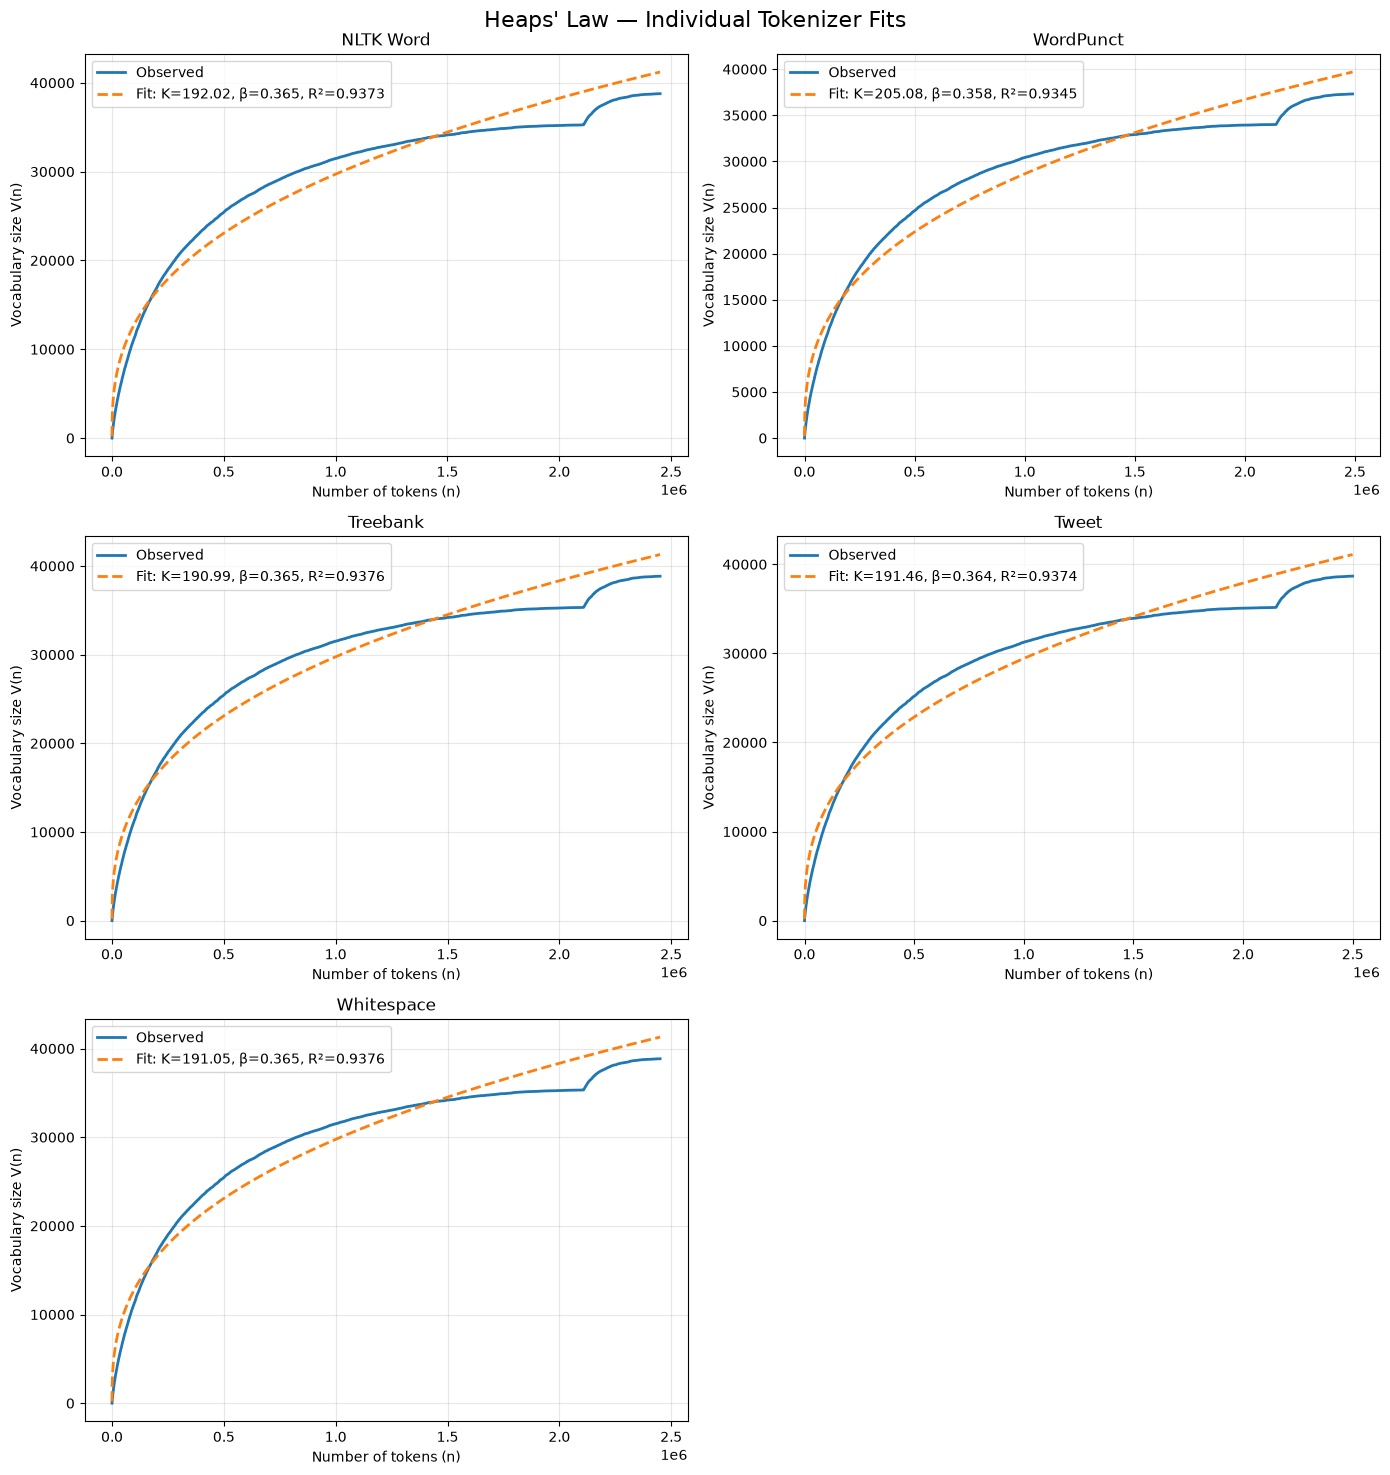

In [15]:
baseline.dataset_analysis.plot_heaps(heaps_curves, heaps_fits)

# Cleanup Comparison

Before BPE pretokenization, a _normalizer_ can clean up the text (unicode normalization, accent stripping, lowercasing). The variants compared here are set in `config.CLEANUP_COMPARISON`; the ones used to train tokenizers for the experiments are set in `config.CLEANUP_VARIANTS`.

## Qualitative

Some sentences with non-ASCII characters under each variant:

In [16]:
cleanup_examples = baseline.tokenization.pick_cleanup_examples(cv_sentences, config.CLEANUP_NUM_EXAMPLES)
print(baseline.tokenization.compare_cleanup_qualitative(cleanup_examples, config.CLEANUP_COMPARISON))

Example 0
variant           text
----------------  -----------------------------------------------------------------------------------------------------------------
raw               Akshuat dendropark ( Russian : Акшуатский дендропарк ) is a natural monument ( Ulyanovsk Oblast protected areas )
lower             akshuat dendropark ( russian : акшуатский дендропарк ) is a natural monument ( ulyanovsk oblast protected areas )
nfkc              Akshuat dendropark ( Russian : Акшуатский дендропарк ) is a natural monument ( Ulyanovsk Oblast protected areas )
nfkc_lower        akshuat dendropark ( russian : акшуатский дендропарк ) is a natural monument ( ulyanovsk oblast protected areas )
nfkd_strip        Akshuat dendropark ( Russian : Акшуатскии дендропарк ) is a natural monument ( Ulyanovsk Oblast protected areas )
nfkd_strip_lower  akshuat dendropark ( russian : акшуатскии дендропарк ) is a natural monument ( ulyanovsk oblast protected areas )

Example 1
variant           text
---------

## Quantitative

Number of unique characters and unique (blank-separated) words in the cross-validation sentences under each variant:

In [17]:
%%time
baseline.tokenization.compare_cleanup_quantitative(cv_sentences, config.CLEANUP_COMPARISON)

Cleanup variants:   0%|          | 0/6 [00:00<?, ?it/s]

CPU times: total: 7.94 s
Wall time: 8.23 s


,variant,steps,unique characters,unique words
0,raw,-,211,38848
1,lower,Lowercase,162,34701
2,nfkc,NFKC,210,38847
3,nfkc_lower,NFKC + Lowercase,161,34700
4,nfkd_strip,NFKD + StripAccents,137,38683
5,nfkd_strip_lower,NFKD + StripAccents + Lowercase,106,34527


# BPE Tokenizers

We train one BPE tokenizer per cleanup variant and vocabulary size (see `config.CLEANUP_VARIANTS` and `config.BPE_VOCAB_SIZES`) on the sentences of `unlabeled_final` train. Trained tokenizers are saved and loaded from the results folder.

In [ ]:
%%time
unlabeled_sentences = baseline.data.unlabeled_corpus(unlabeled)
print(f"Tokenizer training corpus: {len(unlabeled_sentences)} sentences")

tokenizers = OrderedDict()
tokenizer_settings = OrderedDict()
for cleanup, vocab_size in itertools.product(config.CLEANUP_VARIANTS, config.BPE_VOCAB_SIZES):
    name = baseline.tokenization.bpe_name(cleanup, vocab_size, config.BPE_MIN_FREQUENCY)
    tokenizers[name] = baseline.tokenization.load_or_train_bpe(
        unlabeled_sentences, cleanup, config.CLEANUP_VARIANTS[cleanup], vocab_size, config.BPE_MIN_FREQUENCY, results_folder
    )
    tokenizer_settings[name] = {
        'cleanup_steps': config.CLEANUP_VARIANTS[cleanup], 
        'vocab_size': vocab_size, 
        'min_frequency': config.BPE_MIN_FREQUENCY,
    }
    print(f"{name}: {tokenizers[name].get_vocab_size()} tokens")

Tokenizer training corpus: 1291304 sentences
bpe-raw-vs1000-mf2: 1000 tokens
bpe-nfkd_strip_lower-vs1000-mf2: 1000 tokens
CPU times: total: 3min 11s
Wall time: 35.3 s


Here we tokenize the first sentence of the cross-validation data with each tokenizer:

In [19]:
print(cv_sentences[0])
for name, tokenizer in tokenizers.items():
    print(f"{name}: {tokenizer.encode(cv_sentences[0]).tokens}")

In Paris , in October 1560 , he secretly met the English ambassador , Nicolas Throckmorton , asking him for a passport to return to England through Scotland .
bpe-raw-vs1000-mf2: ['▁In', '▁P', 'ar', 'is', '▁,', '▁in', '▁O', 'ct', 'o', 'ber', '▁1', '5', '6', '0', '▁,', '▁he', '▁sec', 're', 't', 'ly', '▁m', 'et', '▁the', '▁E', 'ng', 'l', 'ish', '▁a', 'm', 'b', 'ass', 'ad', 'or', '▁,', '▁N', 'ic', 'ol', 'as', '▁Th', 'ro', 'ck', 'm', 'ort', 'on', '▁,', '▁as', 'k', 'ing', '▁h', 'im', '▁for', '▁a', '▁p', 'ass', 'port', '▁to', '▁re', 't', 'urn', '▁to', '▁E', 'ng', 'land', '▁th', 'ro', 'u', 'gh', '▁S', 'c', 'ot', 'land', '▁.']
bpe-nfkd_strip_lower-vs1000-mf2: ['▁in', '▁par', 'is', '▁,', '▁in', '▁o', 'ct', 'o', 'ber', '▁1', '5', '6', '0', '▁,', '▁he', '▁sec', 're', 't', 'ly', '▁met', '▁the', '▁eng', 'l', 'ish', '▁am', 'b', 'ass', 'ad', 'or', '▁,', '▁n', 'ic', 'ol', 'as', '▁th', 'ro', 'ck', 'm', 'ort', 'on', '▁,', '▁as', 'k', 'ing', '▁him', '▁for', '▁a', '▁p', 'ass', 'port', '▁to', '▁ret', 'urn'

# Encoders and Pair Modes

The tutorial's encoders represent one text, but our inputs are pairs $(s_1, s_2)$. A `PairEncoder` applies a base encoder $h$ (token indicator or bag-of-words) to each sentence and combines the results according to a pair mode:

* `overlap`: $[\min(h(s_1), h(s_2)), |h(s_1) - h(s_2)|]$, what is in both sentences followed by what is in only one;
* `stack`: $[h(s_1), h(s_2)]$;
* `concat_text`: $h(s_1 + " " + s_2)$.

Here is what each combination gives for the first pair:

In [20]:
demo_tokenizer = next(iter(tokenizers.values()))
demo_pair = cv_pairs[0][0]
for encoder_option, pair_mode in itertools.product(baseline.experiment.ENCODER_TYPES, baseline.clslib.PAIR_MODES):
    demo_encoder = baseline.experiment.make_pair_encoder(demo_tokenizer, encoder_option, pair_mode)
    h = demo_encoder(demo_pair)
    print(f"{encoder_option:9s} {pair_mode:11s}: dimensions={len(h)}, non-zero={int((h != 0).sum())}, sum={h.sum():.0f}")

indicator overlap    : dimensions=2000, non-zero=63, sum=63
indicator stack      : dimensions=2000, non-zero=122, sum=122
indicator concat_text: dimensions=1000, non-zero=63, sum=63
bow       overlap    : dimensions=2000, non-zero=63, sum=75
bow       stack      : dimensions=2000, non-zero=122, sum=146
bow       concat_text: dimensions=1000, non-zero=63, sum=146


# Cross Validation Splits

We split the cross-validation pairs into `config.NUM_FOLDS` folds, once per seed in `config.SEEDS`.

In [21]:
%%time
my_cross_validation_sets = []
for seed in config.SEEDS:  
    my_cross_validation_sets.append(
        baseline.data.cross_validation_split(
            pairs=cv_pairs, 
            k=config.NUM_FOLDS,
            seed=seed
        )
    )

CPU times: total: 297 ms
Wall time: 299 ms


# Experiments

We run every combination of tokenizer, encoder, pair mode and model in the config. Each system is saved under `results/{system}/seed-{seed}/fold-{fold}`; folds that were already trained are loaded instead of retrained.

In [22]:
%%time
my_classifiers = OrderedDict()
my_encoders = OrderedDict()  # system name -> (encoder, vectorizer), used again on the test set

for tokenizer_name, encoder_option, pair_mode, model_option in itertools.product(tokenizers, config.ENCODERS, config.PAIR_MODES, config.MODELS):
    name = baseline.experiment.system_name(model_option, encoder_option, pair_mode, tokenizer_name)
    print(name)
    encoder = baseline.experiment.make_pair_encoder(tokenizers[tokenizer_name], encoder_option, pair_mode)
    my_encoders[name] = (encoder, baseline.smlp.vectorize)
    my_classifiers[name] = baseline.experiment.run_system(
        name=name,
        cross_validation_sets=my_cross_validation_sets,
        seeds=config.SEEDS,
        outcome_space=paws_outcome_space,
        encoder=encoder,
        vectorizer=baseline.smlp.vectorize,
        model_option=model_option,
        model_args=config.MODEL_ARGS[model_option],
        system_config={
            'tokenizer': tokenizer_name,
            'tokenizer_settings': tokenizer_settings[tokenizer_name],
            'encoder': encoder_option,
            'pair_mode': pair_mode,
            'model': model_option,
            'model_args': config.MODEL_ARGS[model_option],
            'num_folds': config.NUM_FOLDS,
        },
        results_folder=results_folder,
        device=config.DEVICE,
    )

linear_indicator-enc_overlap_bpe-raw-vs1000-mf2


  0%|          | 0/5 [00:00<?, ?it/s]

c:\Users\joeyl\Documents\GitHub\nlp1-student\part1\baseline\smlp.py:108: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

...

mlp_bow-enc_overlap_bpe-nfkd_strip_lower-vs1000-mf2


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

CPU times: total: 17h 48min 3s
Wall time: 5h 17min 5s


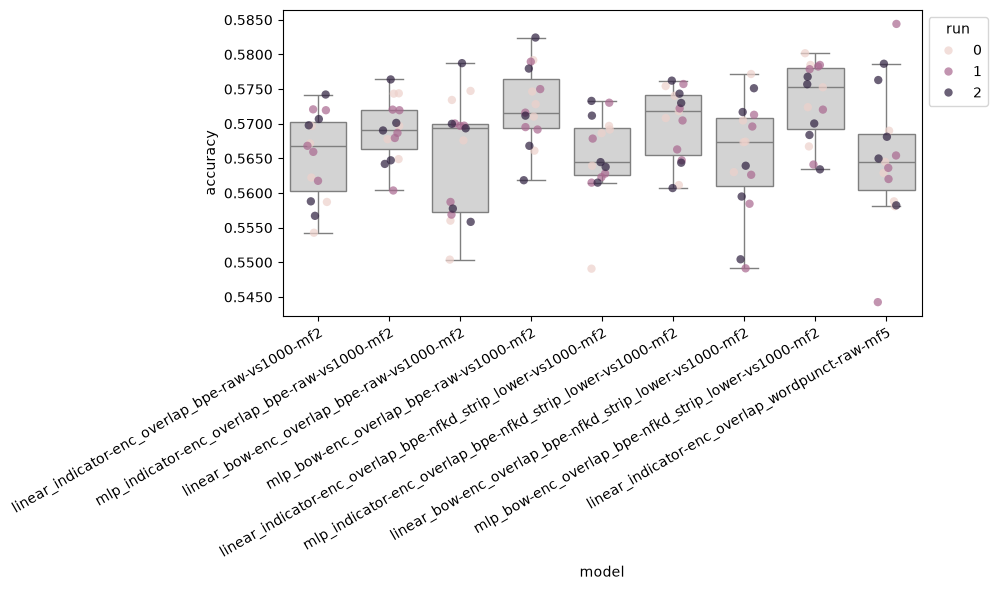

In [35]:
baseline.analysis.plot_box_and_points(baseline.analysis.make_data_frame(my_classifiers), figsize=(10, 6))

In [24]:
baseline.analysis.make_data_frame(my_classifiers).groupby('model', sort=False)['accuracy'].agg(['mean', 'std'])

,mean,std
model,,
linear_indicator-enc_overlap_bpe-raw-vs1000-mf2,0.565385,0.006251
mlp_indicator-enc_overlap_bpe-raw-vs1000-mf2,0.569102,0.004369
linear_bow-enc_overlap_bpe-raw-vs1000-mf2,0.565257,0.008495
mlp_bow-enc_overlap_bpe-raw-vs1000-mf2,0.572551,0.005589
linear_indicator-enc_overlap_bpe-nfkd_strip_lower-vs1000-mf2,0.565478,0.006105
mlp_indicator-enc_overlap_bpe-nfkd_strip_lower-vs1000-mf2,0.570089,0.005292
linear_bow-enc_overlap_bpe-nfkd_strip_lower-vs1000-mf2,0.565147,0.008216
mlp_bow-enc_overlap_bpe-nfkd_strip_lower-vs1000-mf2,0.573207,0.005547


# WordPunct Run

A separate run with a linguistically-informed word tokenizer: token indicators over a word vocabulary built with NLTK's `wordpunct_tokenize` on the sentences of `unlabeled_final` train (words occurring at least `config.WORDPUNCT_MIN_FREQUENCY` times). The vocabulary is large, so this encoder returns sparse rows (see `wordpunct.py`). Models are set in `config.WORDPUNCT_MODELS`.

In [25]:
%%time
wordpunct_steps = config.CLEANUP_COMPARISON[config.WORDPUNCT_CLEANUP]
wordpunct_vocab = baseline.wordpunct.load_or_build_vocab(
    unlabeled_sentences, config.WORDPUNCT_CLEANUP, wordpunct_steps, config.WORDPUNCT_MIN_FREQUENCY, results_folder
)
print(f"Wordpunct vocabulary: {len(wordpunct_vocab)} words")

Counting words:   0%|          | 0/1291304 [00:00<?, ?it/s]

Wordpunct vocabulary: 142245 words
CPU times: total: 31.2 s
Wall time: 33.4 s


In [26]:
%%time
wordpunct_tokenizer_name = baseline.wordpunct.wordpunct_name(config.WORDPUNCT_CLEANUP, config.WORDPUNCT_MIN_FREQUENCY)
wordpunct_encoder = baseline.wordpunct.WordPunctPairIndicator(
    wordpunct_vocab, baseline.tokenization.make_normalizer(wordpunct_steps), config.WORDPUNCT_PAIR_MODE
)

for model_option in config.WORDPUNCT_MODELS:
    name = baseline.experiment.system_name(model_option, 'indicator', config.WORDPUNCT_PAIR_MODE, wordpunct_tokenizer_name)
    print(name)
    my_encoders[name] = (wordpunct_encoder, baseline.wordpunct.vectorize)
    my_classifiers[name] = baseline.experiment.run_system(
        name=name,
        cross_validation_sets=my_cross_validation_sets,
        seeds=config.SEEDS,
        outcome_space=paws_outcome_space,
        encoder=wordpunct_encoder,
        vectorizer=baseline.wordpunct.vectorize,
        model_option=model_option,
        model_args=config.MODEL_ARGS[model_option],
        system_config={
            'tokenizer': wordpunct_tokenizer_name,
            'tokenizer_settings': {'cleanup_steps': wordpunct_steps, 'min_frequency': config.WORDPUNCT_MIN_FREQUENCY},
            'encoder': 'indicator',
            'pair_mode': config.WORDPUNCT_PAIR_MODE,
            'model': model_option,
            'model_args': config.MODEL_ARGS[model_option],
            'num_folds': config.NUM_FOLDS,
        },
        results_folder=results_folder,
        device=config.DEVICE,
    )

linear_indicator-enc_overlap_wordpunct-raw-mf5


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

CPU times: total: 2h 5min 36s
Wall time: 18min 30s


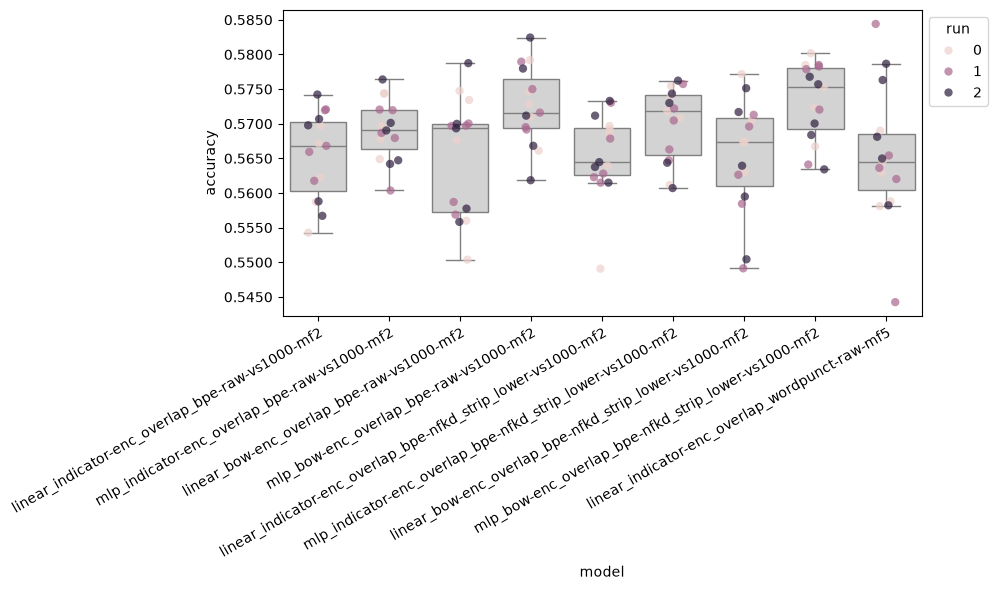

In [34]:
baseline.analysis.plot_box_and_points(baseline.analysis.make_data_frame(my_classifiers), figsize=(10, 6))

# Picking Amongst Design Choices

We compare systems with the Bayesian correlated t-test from the tutorial, in relation to a ROPE of `config.ROPE_SIZE`. All `len(config.SEEDS) * config.NUM_FOLDS` accuracies of a system are used, and the number of runs (seeds) is passed on, so that the correlation between folds is accounted for correctly.

## All pairs

In [28]:
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(baseline.analysis.compare_all_pairs(my_classifiers, config.ROPE_SIZE))

,A,B,P(A wins),P(tie),P(B wins),mean diff (B-A),effect size
0,linear_indicator-enc_overlap_bpe-raw-vs1000-mf2,mlp_indicator-enc_overlap_bpe-raw-vs1000-mf2,0.010341,0.636250,0.353409,0.003717,1.111703
1,linear_indicator-enc_overlap_bpe-raw-vs1000-mf2,linear_bow-enc_overlap_bpe-raw-vs1000-mf2,0.169391,0.673143,0.157465,-0.000128,-0.025952
2,linear_indicator-enc_overlap_bpe-raw-vs1000-mf2,mlp_bow-enc_overlap_bpe-raw-vs1000-mf2,0.000413,0.231064,0.768523,0.007166,2.496815
3,linear_indicator-enc_overlap_bpe-raw-vs1000-mf2,linear_indicator-enc_overlap_bpe-nfkd_strip_lower-vs1000-mf2,0.135815,0.719800,0.144385,0.000093,0.020892
4,linear_indicator-enc_overlap_bpe-raw-vs1000-mf2,mlp_indicator-enc_overlap_bpe-nfkd_strip_lower-vs1000-mf2,0.010235,0.520988,0.468777,0.004704,1.266399
5,linear_indicator-enc_overlap_bpe-raw-vs1000-mf2,linear_bow-enc_overlap_bpe-nfkd_strip_lower-vs1000-mf2,0.182808,0.656625,0.160566,-0.000238,-0.046757
6,linear_indicator-enc_overlap_bpe-raw-vs1000-mf2,mlp_bow-enc_overlap_bpe-nfkd_strip_lower-vs1000-mf2,0.001535,0.220957,0.777508,0.007822,2.178489
7,linear_indicator-enc_overlap_bpe-raw-vs1000-mf2,linear_indicator-enc_overlap_wordpunct-raw-mf5,0.199380,0.610340,0.190279,-0.000099,-0.017512
8,mlp_indicator-enc_overlap_bpe-raw-vs1000-mf2,linear_bow-enc_overlap_bpe-raw-vs1000-mf2,0.395586,0.575455,0.028959,-0.003844,-0.897742
9,mlp_indicator-enc_overlap_bpe-raw-vs1000-mf2,mlp_bow-enc_overlap_bpe-raw-vs1000-mf2,0.006926,0.686136,0.306938,0.003449,1.147930


## Selected comparisons

Posterior plots for the pairs in `config.ROPE_COMPARISONS`.

A=linear_indicator-enc_overlap_bpe-raw-vs1000-mf2 B=linear_indicator-enc_overlap_bpe-nfkd_strip_lower-vs1000-mf2: P(A wins)=0.1358 P(Tie)=0.7198 P(B wins)=0.1444 Effect Size=0.02


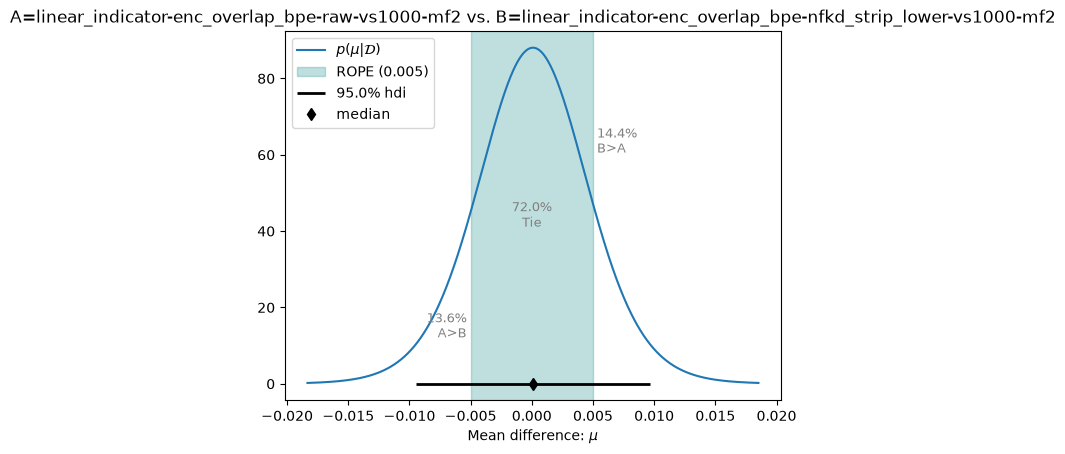

A=linear_indicator-enc_overlap_bpe-raw-vs1000-mf2 B=linear_bow-enc_overlap_bpe-raw-vs1000-mf2: P(A wins)=0.1694 P(Tie)=0.6731 P(B wins)=0.1575 Effect Size=-0.03


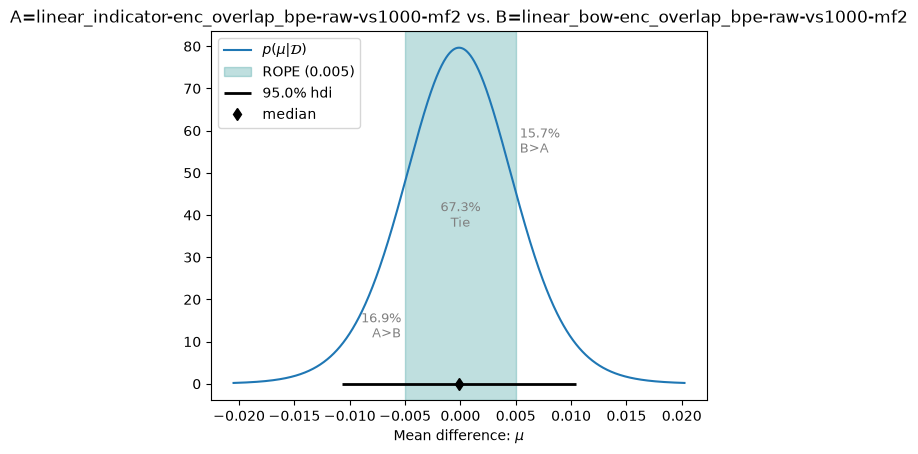

A=linear_indicator-enc_overlap_bpe-raw-vs1000-mf2 B=mlp_indicator-enc_overlap_bpe-raw-vs1000-mf2: P(A wins)=0.0103 P(Tie)=0.6363 P(B wins)=0.3534 Effect Size=1.11


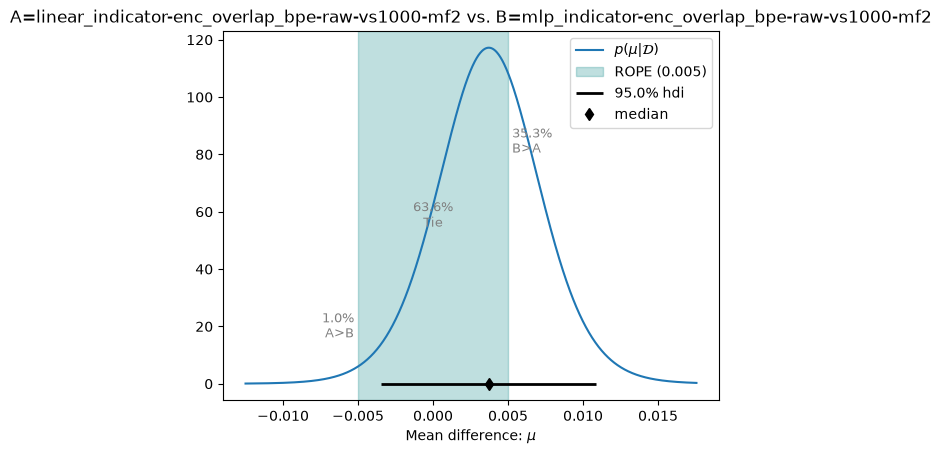

A=linear_indicator-enc_overlap_bpe-raw-vs1000-mf2 B=linear_indicator-enc_overlap_wordpunct-raw-mf5: P(A wins)=0.1994 P(Tie)=0.6103 P(B wins)=0.1903 Effect Size=-0.02


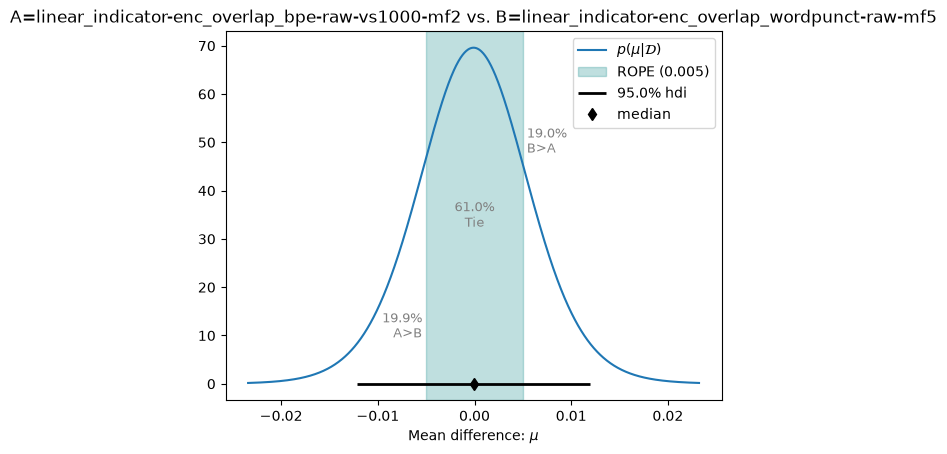

In [32]:
baseline.analysis.plot_comparisons(my_classifiers, config.ROPE_COMPARISONS, config.ROPE_SIZE)

# Test Set: Single Model vs Ensemble

This is the only place where the test set is used. For every system we compare a single model (first seed, first fold) to a majority vote ensemble of all its `len(config.SEEDS) * config.NUM_FOLDS` models.

In [36]:
%%time
test_inputs = [x for x, label in test_pairs]
test_labels = [label for x, label in test_pairs]

test_predictions = OrderedDict()
for name, (encoder, vectorizer) in my_encoders.items():
    x_test = vectorizer(test_inputs, encoder)
    test_predictions[name] = baseline.experiment.single_and_ensemble_predictions(my_classifiers[name], x_test, config.DEVICE)

CPU times: total: 14min 13s
Wall time: 2min 44s


In [37]:
pd.DataFrame(
    [[name, accuracy_score(test_labels, preds['single']), accuracy_score(test_labels, preds['ensemble'])] for name, preds in test_predictions.items()],
    columns=['model', 'single accuracy', 'ensemble accuracy'],
)

,model,single accuracy,ensemble accuracy
0,linear_indicator-enc_overlap_bpe-raw-vs1000-mf2,0.558375,0.567500
1,mlp_indicator-enc_overlap_bpe-raw-vs1000-mf2,0.562125,0.567125
2,linear_bow-enc_overlap_bpe-raw-vs1000-mf2,0.553500,0.567125
3,mlp_bow-enc_overlap_bpe-raw-vs1000-mf2,0.565375,0.571875
4,linear_indicator-enc_overlap_bpe-nfkd_strip_lo...,0.559250,0.566375
5,mlp_indicator-enc_overlap_bpe-nfkd_strip_lower...,0.565125,0.563500
6,linear_bow-enc_overlap_bpe-nfkd_strip_lower-vs...,0.561125,0.567000
7,mlp_bow-enc_overlap_bpe-nfkd_strip_lower-vs100...,0.570125,0.572625
8,linear_indicator-enc_overlap_wordpunct-raw-mf5,0.561750,0.562250


## Classification reports

In [38]:
for name, preds in test_predictions.items():
    print(f"===== {name} =====")
    print("Single model")
    print(classification_report(test_labels, preds['single'], target_names=paws_outcome_space.names, digits=4))
    print("Ensemble")
    print(classification_report(test_labels, preds['ensemble'], target_names=paws_outcome_space.names, digits=4))

===== linear_indicator-enc_overlap_bpe-raw-vs1000-mf2 =====
Single model
                precision    recall  f1-score   support

not paraphrase     0.5765    0.7856    0.6650      4464
    paraphrase     0.5008    0.2715    0.3521      3536

      accuracy                         0.5584      8000
     macro avg     0.5387    0.5286    0.5086      8000
  weighted avg     0.5430    0.5584    0.5267      8000

Ensemble
                precision    recall  f1-score   support

not paraphrase     0.5740    0.8725    0.6924      4464
    paraphrase     0.5313    0.1824    0.2716      3536

      accuracy                         0.5675      8000
     macro avg     0.5526    0.5275    0.4820      8000
  weighted avg     0.5551    0.5675    0.5064      8000

===== mlp_indicator-enc_overlap_bpe-raw-vs1000-mf2 =====
Single model
                precision    recall  f1-score   support

not paraphrase     0.5661    0.9218    0.7014      4464
    paraphrase     0.5226    0.1080    0.1790      3536

